# Explainability: Best Models for each Configuration

In [21]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import shap
shap.initjs()

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

In [22]:
df_train = pd.read_csv('/Users/laviniarotellini/Desktop/Laurea/Tesi/Costruzione e Analisi DF/5. Classification/df_train.csv')
df_test = pd.read_csv('/Users/laviniarotellini/Desktop/Laurea/Tesi/Costruzione e Analisi DF/5. Classification/df_test.csv')

In [23]:
n_classes = 3

In [24]:
lab_encoder = joblib.load('/Users/laviniarotellini/Desktop/Laurea/Tesi/Costruzione e Analisi DF/3. Data Understanding and Prep/label_encoder.pkl')

1. 

In [25]:
y_test = df_test['target']
x_test = df_test.drop('target', axis=1)

In [26]:
y = df_train['target']
X = df_train.drop('target', axis = 1)

In [27]:
x_train, x_val, y_train, y_val = train_test_split(X, y, test_size=0.4, random_state=42, stratify=y)

In [28]:
columns_to_scale = df_train.filter(regex=r"\d{4}").columns.tolist()
scaler = StandardScaler()

x_train[columns_to_scale] = scaler.fit_transform(x_train[columns_to_scale])
x_val[columns_to_scale]   = scaler.transform(x_val[columns_to_scale])
x_test[columns_to_scale]  = scaler.transform(x_test[columns_to_scale])

In [29]:
x_train.shape

(344, 301)

2. Caricamento dei modelli migliori con e senza city

In [ ]:
model_city = joblib.load('/Users/laviniarotellini/Library/CloudStorage/OneDrive-UniversityofPisa(2)/models-tesi/Modelli a quattro anni con city/rf_finale_quattro.pkl')
#model_no_city = joblib.load('/Users/laviniarotellini/Library/CloudStorage/OneDrive-UniversityofPisa(2)/models-tesi/Modelli a quattro anni senza city/_logreg_quattro_nocity.pkl')

### 3. SHAP

3.1 City

In [31]:
x_train = x_train.astype(np.float64)
x_val = x_val.astype(np.float64)
x_test = x_test.astype(np.float64)

In [32]:
explainer = shap.TreeExplainer(model_city)
shap_values_city = explainer.shap_values(x_train)

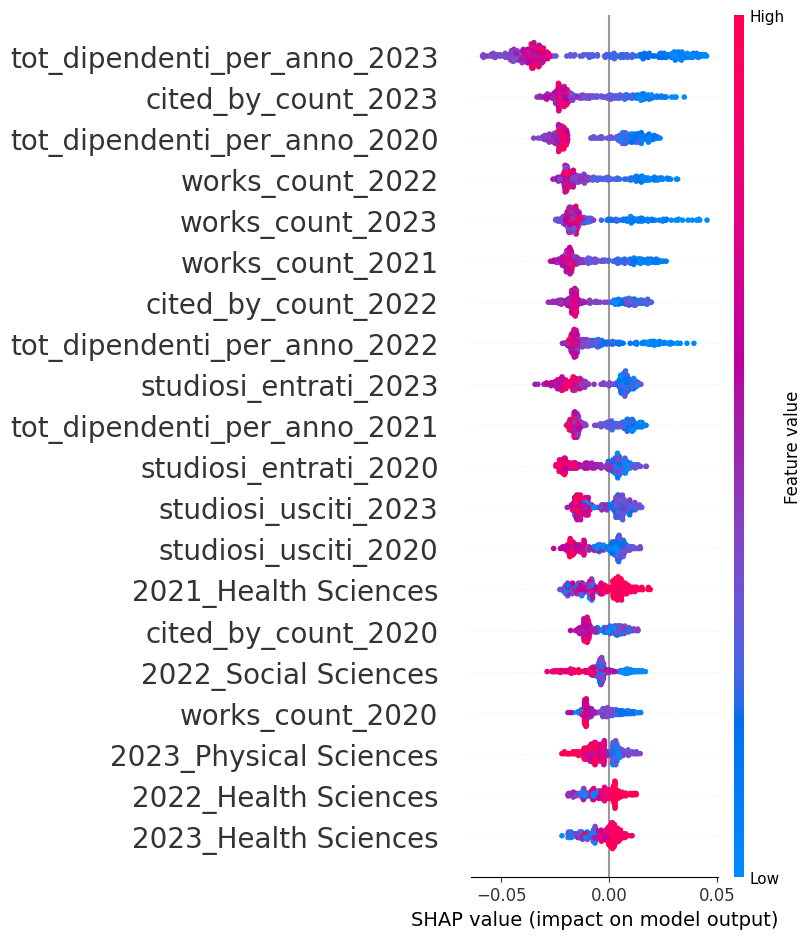

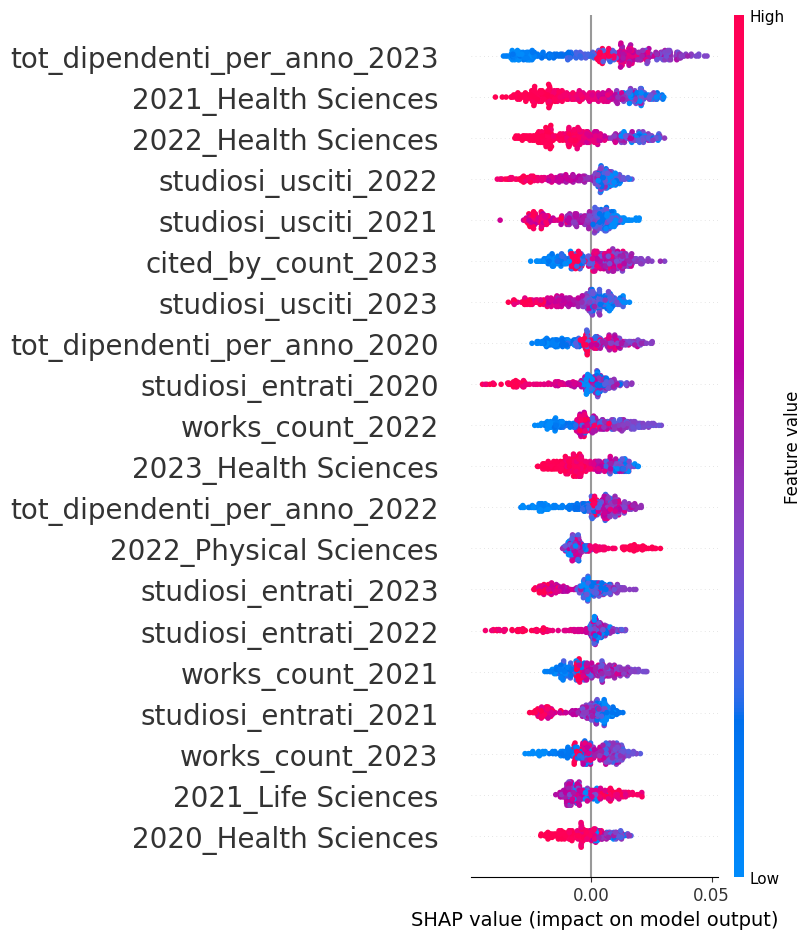

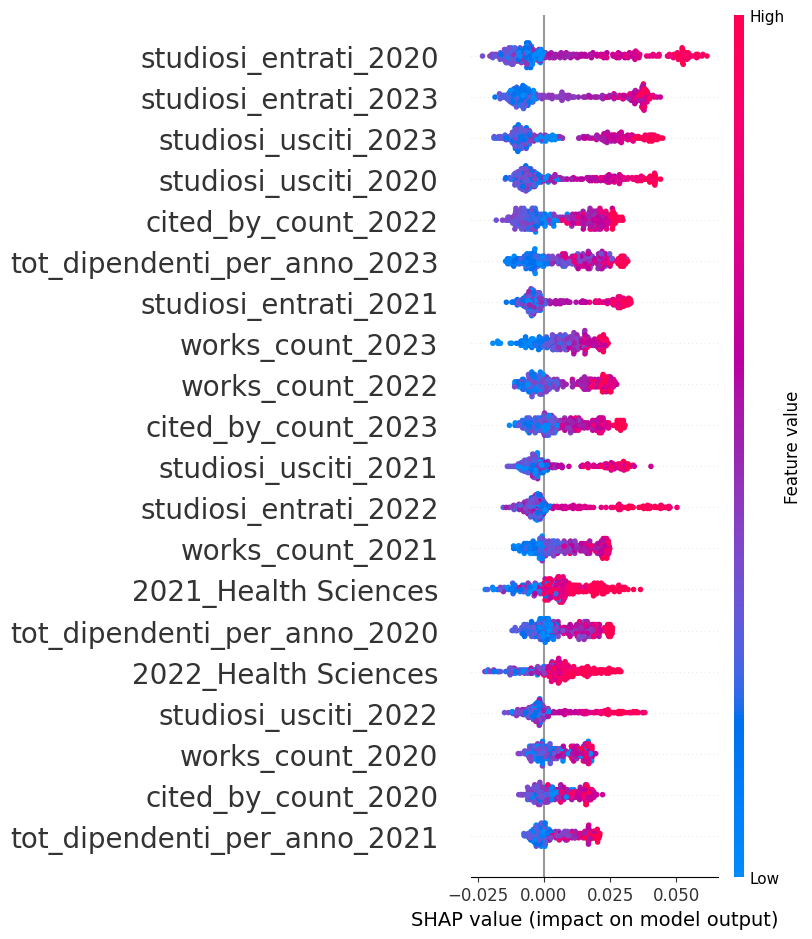

In [33]:
import os
import matplotlib.pyplot as plt

save_dir = "/Users/laviniarotellini/Downloads/Template_tesi_di_laurea_in_Informatica_Umanistica__Università_di_Pisa_/immagini/xai"

for i in range(n_classes):
    plt.figure()
    shap.summary_plot(
        shap_values_city[:, :, i],
        x_train,
        show=False  # ← importante: non mostrare subito
    )
    
    ax = plt.gca()
    ax.set_yticklabels(ax.get_yticklabels(), fontsize=20)  # label features (asse Y)
    ax.set_xlabel(ax.get_xlabel(), fontsize=14)             # label asse X
    ax.tick_params(axis='x', labelsize=12)                  # tick asse X
    
    plt.tight_layout()
    plt.savefig(f"classe_{i}.png", dpi=150, bbox_inches='tight')
    plt.show()

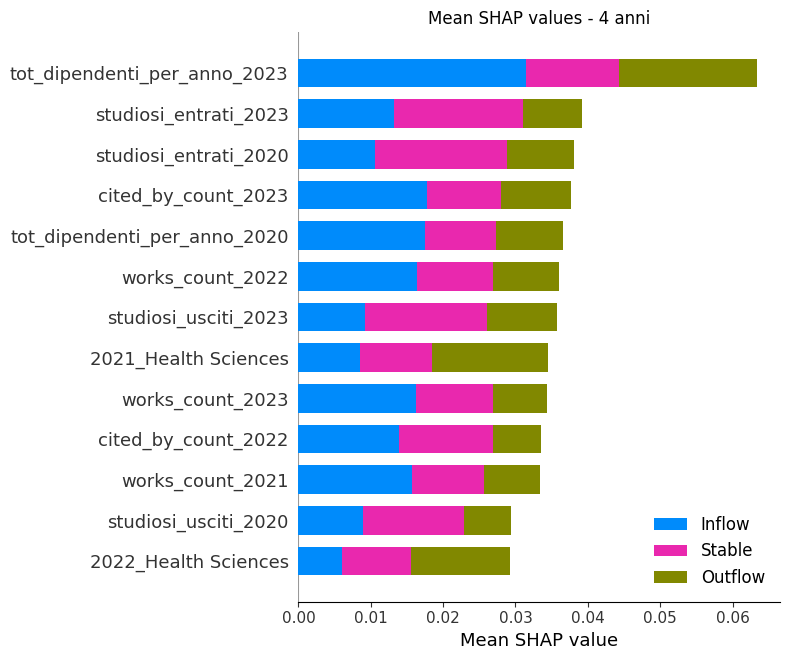

In [34]:
shap.summary_plot(shap_values_city, x_train, plot_type="bar", max_display=13, show= False, class_names = ['Inflow', 'Outflow', 'Stable'] )
plt.xlabel("Mean SHAP value")
plt.title("Mean SHAP values - 4 anni")
plt.tight_layout()
plt.show()

In [35]:
feature_names = x_train.columns.tolist()

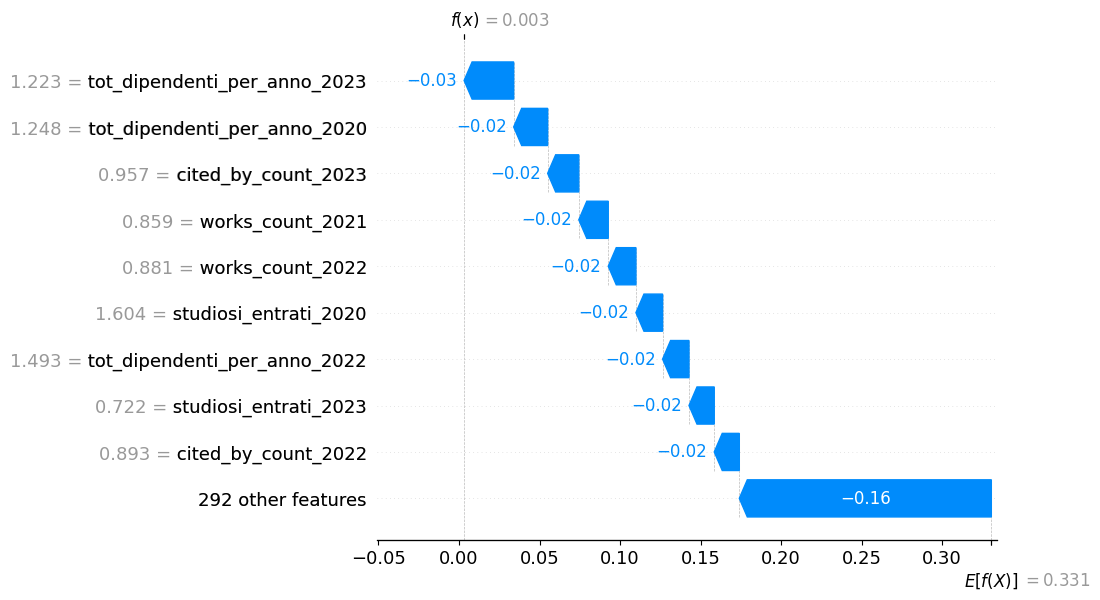

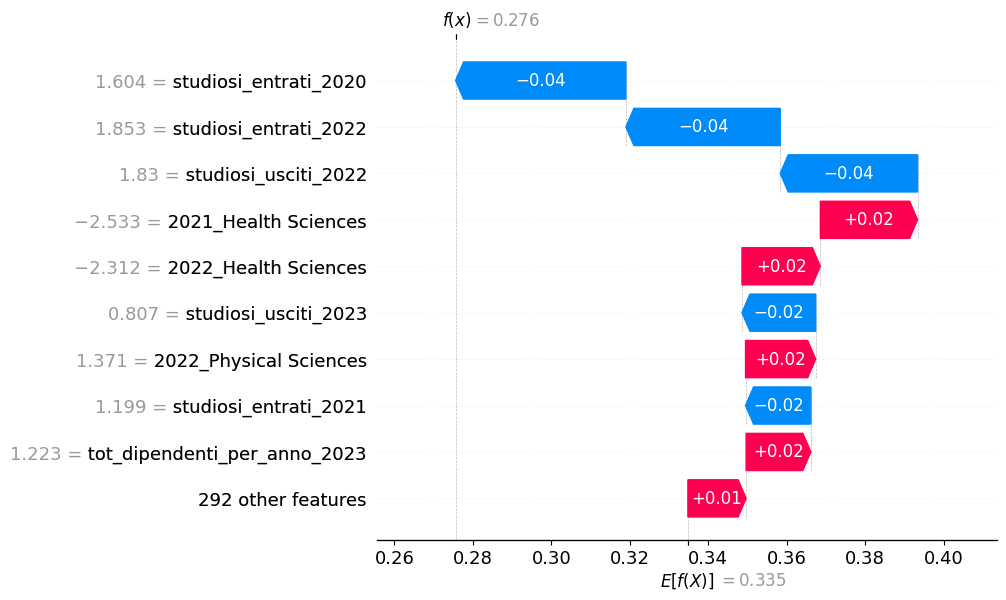

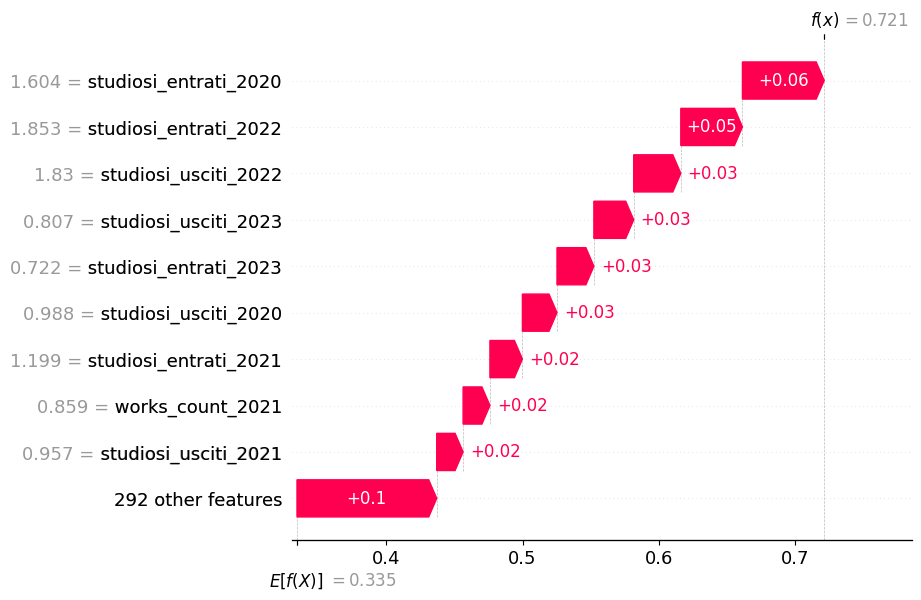

In [36]:
for i in range(n_classes):
    shap.plots.waterfall(
        shap.Explanation(
            values=shap_values_city[0, :, i],
            base_values=explainer.expected_value[i],
            data=x_train.iloc[0, :].values,
            feature_names=feature_names
        )
    )

4.1 Ri Allenamento del modello

In [37]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import confusion_matrix, f1_score, accuracy_score, classification_report
from sklearn.ensemble import RandomForestClassifier

In [38]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [39]:
# Estrai i valori dall'oggetto Explanation
shap_vals = (
    shap_values_city.values
    if hasattr(shap_values_city, "values")
    else np.stack(shap_values_city, axis=2)
)

# Se ha 3 dimensioni (multiclass), fai mean su samples e classes
shap_importance_city = np.mean(np.abs(shap_vals), axis=(0, 2))

In [40]:
# feature_importance = pd.DataFrame({
#     "feature": X.columns,
#     "mean_abs_shap": shap_importance_city
# }).sort_values("mean_abs_shap", ascending=False)

# top_features = feature_importance.head(13)
# print(top_features)

In [41]:
rf_params = {
    'n_estimators' : [10, 100, 500],
    'criterion' : ['gini', 'entropy', 'log_loss'],
    'max_depth' : [10, 20, 30, 100], 
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'class_weight': ['balanced'],
    'max_features' : ['sqrt', 'log2']
}

rf_grid = GridSearchCV(RandomForestClassifier(),
                       rf_params, 
                       cv = cv,
                       verbose = 1,
                       n_jobs = -1, 
                       scoring= 'f1_macro')

validation_dict = {}

In [42]:
from sklearn.model_selection import cross_val_score

def different_idx_corrected(shap_values, X_train_df, y_train):
    
    shap_importance = np.mean(np.abs(shap_values), axis=(0, 2))
    
    best_f1       = -1
    best_model    = None
    best_features = None
    results_dict  = {}

    for i in range(10, 30):
        top_idx      = np.argsort(shap_importance)[::-1][:i]
        top_features = np.array(X_train_df.columns)[top_idx]
        
        X_train_top = X_train_df[top_features]
        
        # 🔹 tuning SOLO su train
        rf_grid.fit(X_train_top, y_train)
        rf = rf_grid.best_estimator_
        
        # 🔹 valutazione con cross-validation (NON validation set!)
        cv_scores = cross_val_score(
            rf,
            X_train_top,
            y_train,
            cv=5,
            scoring='f1_macro',
            n_jobs=-1
        )
        
        mean_f1 = cv_scores.mean()
        
        results_dict[i] = {
            'n_features' : i,
            'cv_f1_macro': round(mean_f1, 4),
            'best_params': rf_grid.best_params_
        }
        
        if mean_f1 > best_f1:
            best_f1       = mean_f1
            best_model    = rf
            best_features = top_features
    
    return results_dict, best_model, best_features

In [43]:
results, rf_model, top_features = different_idx_corrected(
    shap_values_city,
    X_train_df=x_train,
    y_train=y_train
)

Fitting 5 folds for each of 648 candidates, totalling 3240 fits
Fitting 5 folds for each of 648 candidates, totalling 3240 fits
Fitting 5 folds for each of 648 candidates, totalling 3240 fits
Fitting 5 folds for each of 648 candidates, totalling 3240 fits
Fitting 5 folds for each of 648 candidates, totalling 3240 fits
Fitting 5 folds for each of 648 candidates, totalling 3240 fits
Fitting 5 folds for each of 648 candidates, totalling 3240 fits
Fitting 5 folds for each of 648 candidates, totalling 3240 fits
Fitting 5 folds for each of 648 candidates, totalling 3240 fits
Fitting 5 folds for each of 648 candidates, totalling 3240 fits
Fitting 5 folds for each of 648 candidates, totalling 3240 fits
Fitting 5 folds for each of 648 candidates, totalling 3240 fits
Fitting 5 folds for each of 648 candidates, totalling 3240 fits
Fitting 5 folds for each of 648 candidates, totalling 3240 fits
Fitting 5 folds for each of 648 candidates, totalling 3240 fits
Fitting 5 folds for each of 648 candidat

In [46]:
df_results = pd.DataFrame(results).T.reset_index(drop=True)
df_results = df_results.sort_values(by='cv_f1_macro', ascending=False)
df_results

,n_features,cv_f1_macro,best_params
0,10,0.4958,"{'class_weight': 'balanced', 'criterion': 'gin..."
2,12,0.4945,"{'class_weight': 'balanced', 'criterion': 'log..."
8,18,0.4866,"{'class_weight': 'balanced', 'criterion': 'gin..."
14,24,0.4771,"{'class_weight': 'balanced', 'criterion': 'ent..."
11,21,0.4745,"{'class_weight': 'balanced', 'criterion': 'gin..."
6,16,0.4726,"{'class_weight': 'balanced', 'criterion': 'ent..."
7,17,0.4648,"{'class_weight': 'balanced', 'criterion': 'gin..."
9,19,0.4638,"{'class_weight': 'balanced', 'criterion': 'ent..."
10,20,0.4562,"{'class_weight': 'balanced', 'criterion': 'ent..."
3,13,0.4477,"{'class_weight': 'balanced', 'criterion': 'ent..."


In [47]:
y_val_pred = rf_model.predict(x_val[top_features])

print(classification_report(y_val, y_val_pred))

              precision    recall  f1-score   support

           0       0.18      0.24      0.20        21
           1       0.52      0.52      0.52        48
           2       0.79      0.76      0.77       161

    accuracy                           0.66       230
   macro avg       0.50      0.51      0.50       230
weighted avg       0.68      0.66      0.67       230



In [48]:
X_full = pd.concat([x_train, x_val])
y_full = pd.concat([y_train, y_val])

X_full_top = X_full[top_features]

final_model = RandomForestClassifier(**rf_model.get_params())
final_model.fit(X_full_top, y_full)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",10
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'log2'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y

5.1 Evaluation

In [49]:
y_test_pred = final_model.predict(x_test[top_features])
    
test_accuracy = accuracy_score(y_test, y_test_pred)
test_f1_weighted = f1_score(y_test, y_test_pred, average='weighted')
test_f1_macro = f1_score(y_test, y_test_pred, average='macro')

In [50]:
print(classification_report(y_test, y_test_pred, 
                                  target_names=lab_encoder.classes_))

              precision    recall  f1-score   support

      inflow       0.33      0.45      0.38        38
     outflow       0.40      0.34      0.37        90
      stable       0.77      0.77      0.77       256

    accuracy                           0.64       384
   macro avg       0.50      0.52      0.51       384
weighted avg       0.64      0.64      0.64       384



### Versione Claude

In [2]:
# %% [markdown]
# # Explainability: modello migliore (quattro anni, con city)
#
# Flusso:
# 1. Stesso split e stesso scaler del notebook di classificazione
# 2. SHAP sul modello finale (rf_finale_quattro.pkl), calcolato sul test set (solo descrittivo)
# 3. Selezione delle top-k feature SENZA leakage:
#    ranking SHAP da un RF addestrato solo su x_train, calcolato su x_val;
#    k scelto con la stessa CV sul solo x_train
# 4. Riaddestramento su train+val con le feature scelte e valutazione sul test

# %%
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import shap

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, accuracy_score, classification_report

RANDOM_STATE = 42

# %%
# --- Percorsi ---
data_dir = '/Users/laviniarotellini/Desktop/Laurea/Tesi/Costruzione e Analisi DF/5. Classification/'
encoder_path = '/Users/laviniarotellini/Desktop/Laurea/Tesi/Costruzione e Analisi DF/3. Data Understanding and Prep/label_encoder.pkl'
model_dir = '/Users/laviniarotellini/Library/CloudStorage/OneDrive-UniversityofPisa(2)/models-tesi/Modelli a quattro anni con city/'
save_dir = '/Users/laviniarotellini/Downloads/Template_tesi_di_laurea_in_Informatica_Umanistica__Università_di_Pisa_/immagini/xai'
os.makedirs(save_dir, exist_ok=True)

# %%
df_train = pd.read_csv(data_dir + 'df_train.csv')
df_test = pd.read_csv(data_dir + 'df_test.csv')

lab_encoder = joblib.load(encoder_path)
class_names = list(lab_encoder.classes_)
n_classes = len(class_names)
print(class_names)

# %% [markdown]
# ## 1. Split e scalatura (identici al notebook di classificazione)

# %%
y = df_train['target']
X = df_train.drop('target', axis=1)

y_test = df_test['target']
x_test = df_test.drop('target', axis=1)

# stesso split del notebook di classificazione
x_train, x_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
x_train, x_val = x_train.copy(), x_val.copy()
x_test = x_test.copy()

# %%
# stesso scaler del notebook di classificazione (fit solo su x_train)
cols_to_scale = X.filter(regex=r"\d{4}").columns.tolist()
print(f'{len(cols_to_scale)} colonne scalate su {X.shape[1]}')
print(cols_to_scale)  # controlla che non ci siano colonne non numeriche/dummy

scaler = StandardScaler()
x_train[cols_to_scale] = scaler.fit_transform(x_train[cols_to_scale])
x_val[cols_to_scale] = scaler.transform(x_val[cols_to_scale])
x_test[cols_to_scale] = scaler.transform(x_test[cols_to_scale])

# stesso ordine di colonne ovunque
x_test = x_test[x_train.columns]

x_train = x_train.astype(np.float64)
x_val = x_val.astype(np.float64)
x_test = x_test.astype(np.float64)

# versione del test in unita' originali (solo per i grafici)
x_test_orig = x_test.copy()
x_test_orig[cols_to_scale] = scaler.inverse_transform(x_test[cols_to_scale])

print(x_train.shape, x_val.shape, x_test.shape)

# %% [markdown]
# ## 2. Caricamento del modello finale

# %%
model_city = joblib.load(model_dir + 'rf_finale_quattro.pkl')

# sanity check: deve coincidere con i risultati del notebook di classificazione
y_pred_check = model_city.predict(x_test)
print('Test F1 macro (model_city):', round(f1_score(y_test, y_pred_check, average='macro'), 4))
print('Test accuracy (model_city):', round(accuracy_score(y_test, y_pred_check), 4))

# iperparametri del modello finale, riusati nella selezione delle feature
rf_best_params = model_city.get_params()
rf_best_params['random_state'] = RANDOM_STATE
print(rf_best_params)

['inflow', 'outflow', 'stable']
36 colonne scalate su 301
['works_count_2023', 'cited_by_count_2023', 'works_count_2022', 'cited_by_count_2022', 'works_count_2021', 'cited_by_count_2021', 'works_count_2020', 'cited_by_count_2020', 'tot_dipendenti_per_anno_2020', 'studiosi_usciti_2020', 'studiosi_entrati_2020', 'tot_dipendenti_per_anno_2021', 'studiosi_usciti_2021', 'studiosi_entrati_2021', 'tot_dipendenti_per_anno_2022', 'studiosi_usciti_2022', 'studiosi_entrati_2022', 'tot_dipendenti_per_anno_2023', 'studiosi_usciti_2023', 'studiosi_entrati_2023', '2020_Health Sciences', '2020_Life Sciences', '2020_Social Sciences', '2020_Physical Sciences', '2021_Health Sciences', '2021_Life Sciences', '2021_Social Sciences', '2021_Physical Sciences', '2022_Health Sciences', '2022_Life Sciences', '2022_Social Sciences', '2022_Physical Sciences', '2023_Health Sciences', '2023_Life Sciences', '2023_Social Sciences', '2023_Physical Sciences']
(459, 301) (115, 301) (384, 301)
Test F1 macro (model_city): 

(384, 301, 3)


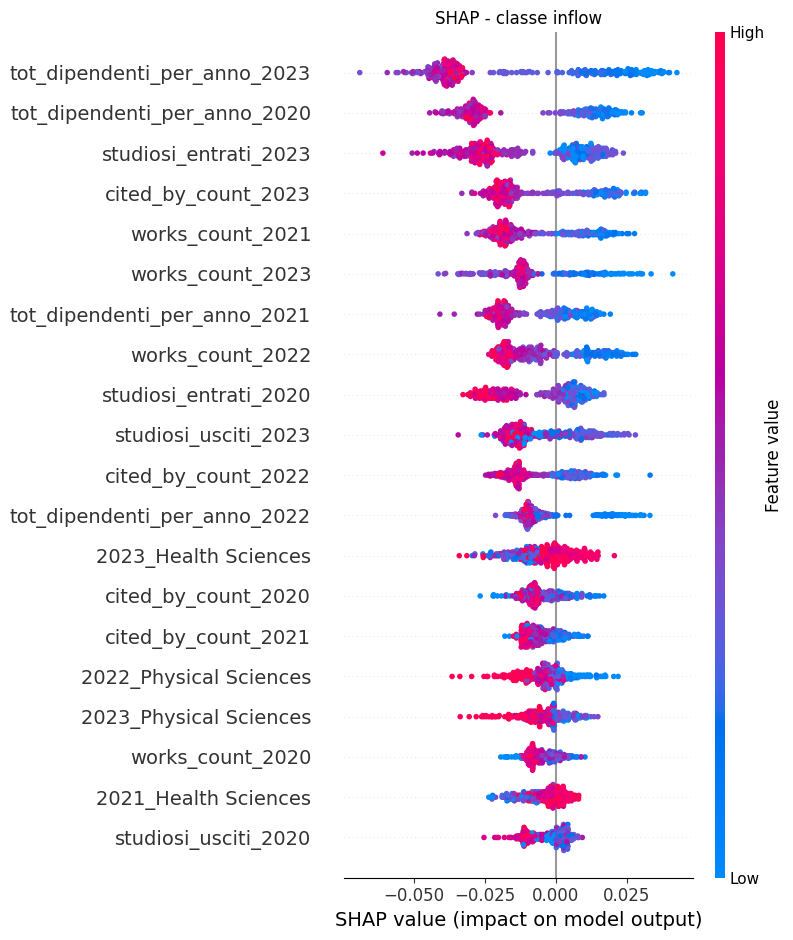

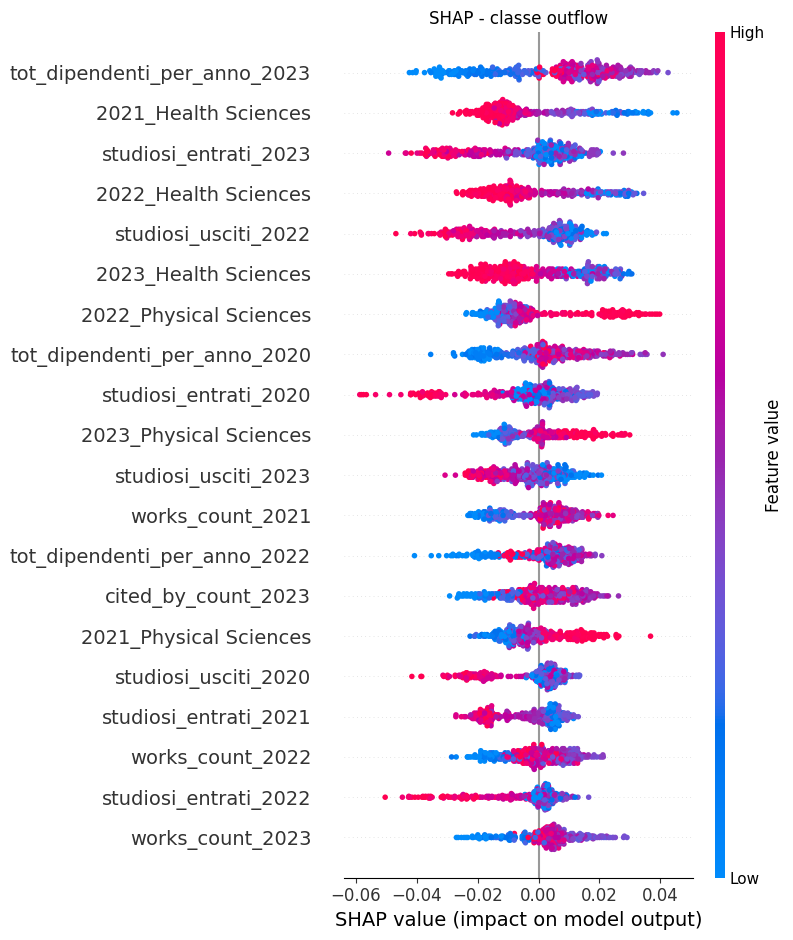

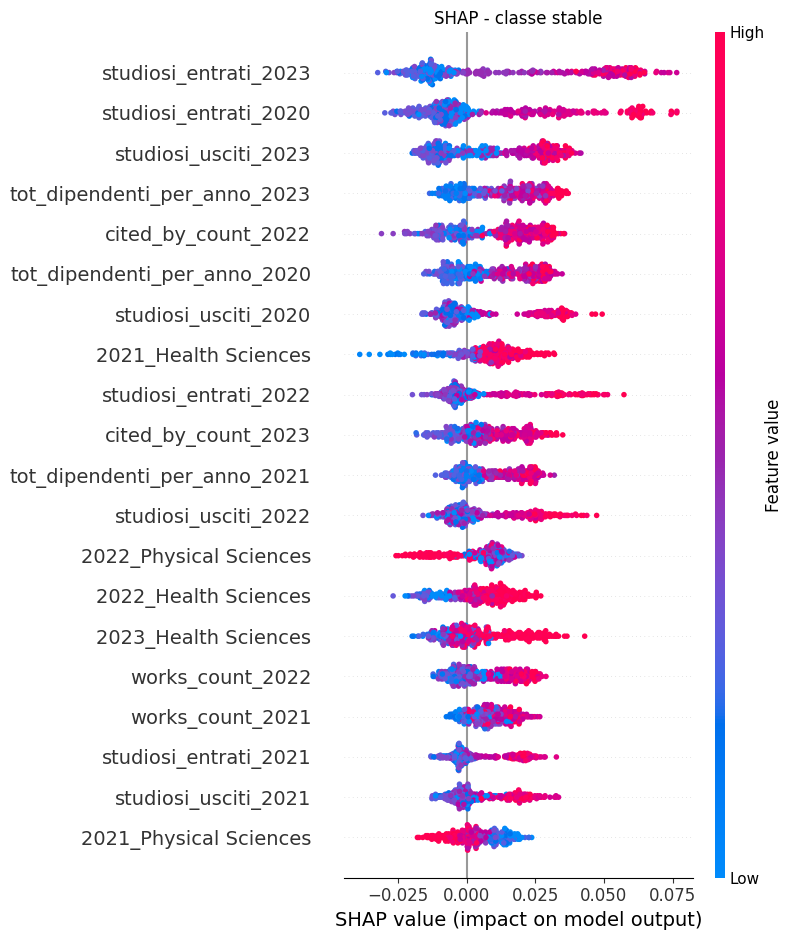

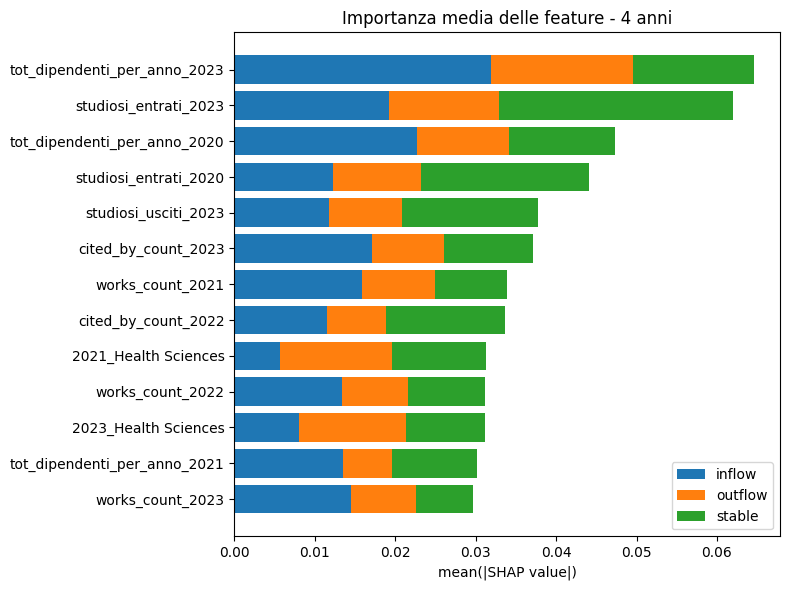

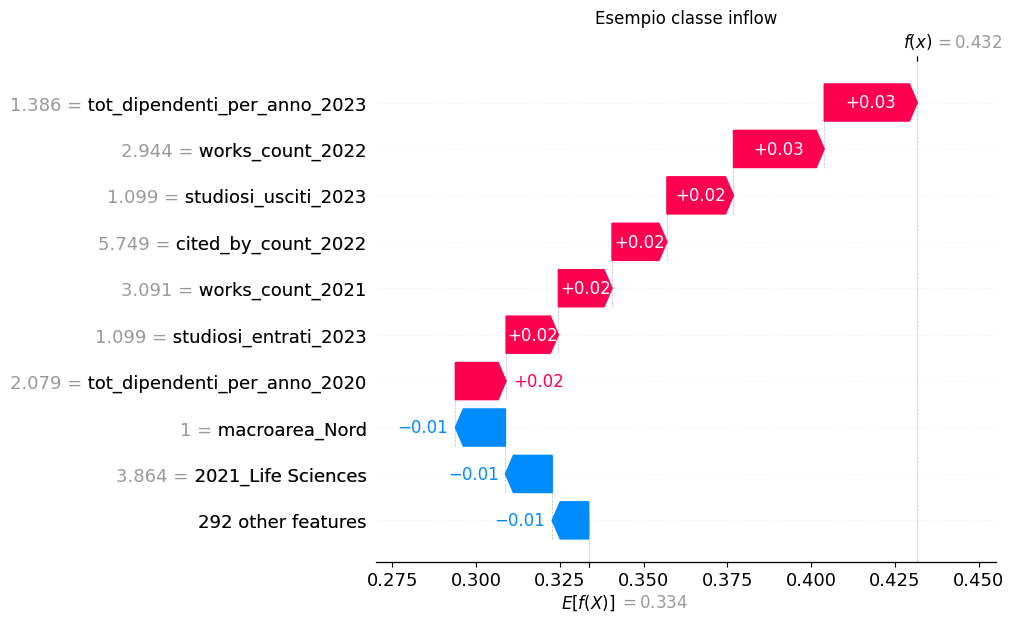

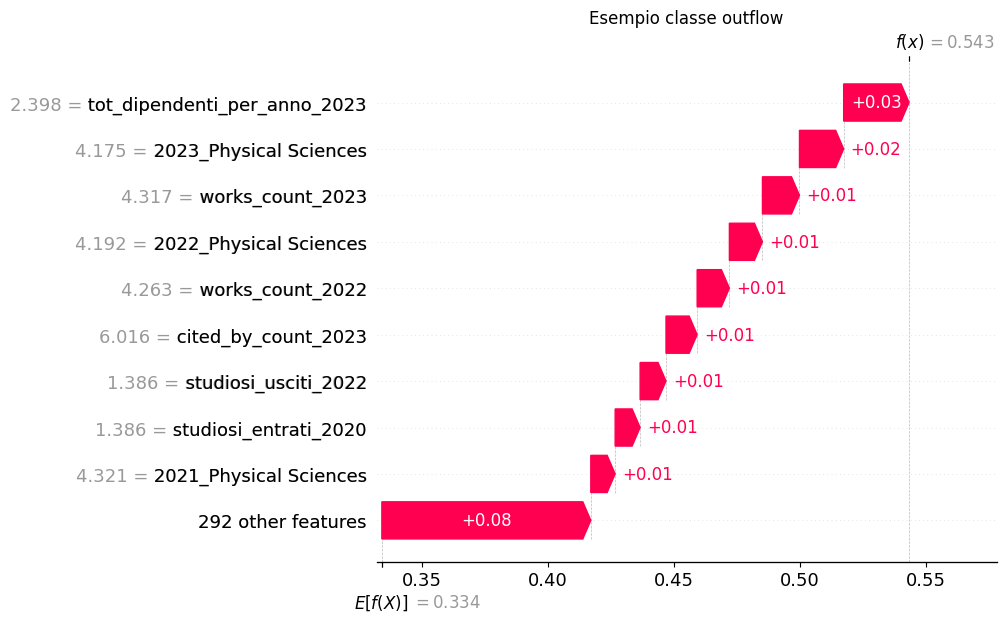

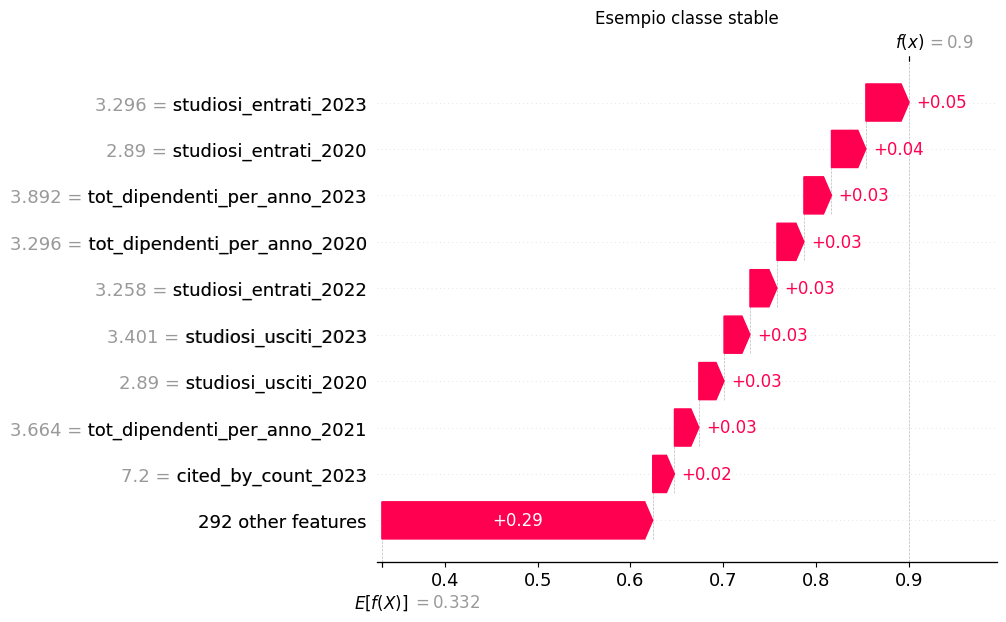

In [3]:
def to_3d(sv):
    """Restituisce sempre un array (campioni, feature, classi),
    indipendentemente dalla versione di SHAP."""
    if hasattr(sv, 'values'):
        sv = sv.values
    if isinstance(sv, list):
        sv = np.stack(sv, axis=2)
    return np.asarray(sv)


N_SAMPLE = 1000
x_test_s = x_test.sample(n=min(N_SAMPLE, len(x_test)), random_state=RANDOM_STATE)
x_test_s_orig = x_test_orig.loc[x_test_s.index]

explainer = shap.TreeExplainer(model_city)
shap_values_city = to_3d(explainer.shap_values(x_test_s))
expected_value = np.atleast_1d(explainer.expected_value)
print(shap_values_city.shape)

# %%
# Summary plot (beeswarm) per classe
for i in range(n_classes):
    plt.figure()
    shap.summary_plot(shap_values_city[:, :, i], x_test_s, show=False)
    plt.title(f'SHAP - classe {class_names[i]}')

    ax = plt.gca()
    ax.tick_params(axis='y', labelsize=14)
    ax.set_xlabel(ax.get_xlabel(), fontsize=14)
    ax.tick_params(axis='x', labelsize=12)

    plt.tight_layout()
    plt.savefig(os.path.join(save_dir, f'classe_{class_names[i]}.png'), dpi=150, bbox_inches='tight')
    plt.show()

# %%
# Importanza media assoluta, impilata per classe (top feature)
mean_abs_per_class = np.mean(np.abs(shap_values_city), axis=0)   # (feature, classi)
total_importance = mean_abs_per_class.sum(axis=1)

top_n = 13
order = np.argsort(total_importance)[::-1][:top_n][::-1]          # ordine crescente per il barh
feat_names = np.array(x_train.columns)

fig, ax = plt.subplots(figsize=(8, 6))
left = np.zeros(len(order))
for i in range(n_classes):
    vals = mean_abs_per_class[order, i]
    ax.barh(feat_names[order], vals, left=left, label=class_names[i])
    left += vals
ax.set_xlabel('mean(|SHAP value|)')
ax.set_title('Importanza media delle feature - 4 anni')
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(save_dir, 'shap_bar_quattro_anni.png'), dpi=150, bbox_inches='tight')
plt.show()

# %%
# Waterfall: per ogni classe un esempio del test correttamente classificato
# (valori delle feature mostrati in unita' originali)
pred_s = model_city.predict(x_test_s)
true_s = y_test.loc[x_test_s.index].values
feature_names = x_train.columns.tolist()

for i in range(n_classes):
    cls_code = i  # assumo target codificato 0..n_classes-1 nello stesso ordine di lab_encoder.classes_
    candidates = np.where((true_s == cls_code) & (pred_s == cls_code))[0]
    if len(candidates) == 0:
        print(f'Nessun esempio correttamente classificato per la classe {class_names[i]}')
        continue
    j = candidates[0]
    shap.plots.waterfall(
        shap.Explanation(
            values=shap_values_city[j, :, i],
            base_values=expected_value[i],
            data=x_test_s_orig.iloc[j].values,
            feature_names=feature_names
        ),
        show=False
    )
    plt.title(f'Esempio classe {class_names[i]}')
    plt.savefig(os.path.join(save_dir, f'waterfall_{class_names[i]}.png'), dpi=150, bbox_inches='tight')
    plt.show()

In [80]:
# ## 4. Selezione delle top-k feature (senza leakage)
# - ranking: RF addestrato SOLO su x_train, SHAP calcolato su x_val
# - scelta di k: CV (stessa per tutti i k) sul solo x_train, iperparametri fissi

# %%
rf_rank = RandomForestClassifier(**rf_best_params)
rf_rank.fit(x_train, y_train)

x_val_s = x_val.sample(n=min(N_SAMPLE, len(x_val)), random_state=RANDOM_STATE)
shap_rank = to_3d(shap.TreeExplainer(rf_rank).shap_values(x_val_s))

# importanza media assoluta su campioni e classi -> un valore per feature
shap_importance = np.mean(np.abs(shap_rank), axis=(0, 2))
assert shap_importance.shape[0] == x_train.shape[1]

ranking = pd.DataFrame({
    'feature': x_train.columns,
    'mean_abs_shap': shap_importance
}).sort_values('mean_abs_shap', ascending=False).reset_index(drop=True)
ranking.head(20)

# %%
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

k_min, k_max = 100, min(121, x_train.shape[1])
results = []

for k in range(k_min, k_max + 1):
    top_k = ranking['feature'].iloc[:k].tolist()
    scores = cross_val_score(
        RandomForestClassifier(**rf_best_params),
        x_train[top_k], y_train,
        cv=cv, scoring='f1_macro', n_jobs=-1
    )
    results.append({'n_features': k,
                    'cv_f1_macro_mean': scores.mean(),
                    'cv_f1_macro_std': scores.std()})

df_results = pd.DataFrame(results).sort_values('cv_f1_macro_mean', ascending=False)
df_results

# %%
best_k = int(df_results.iloc[0]['n_features'])
top_features = ranking['feature'].iloc[:best_k].tolist()
print(f'k scelto: {best_k}')
print(top_features)

# %%
# Controllo sul validation (il ranking usa x_val senza etichette: la stima resta indicativa)
rf_sel = RandomForestClassifier(**rf_best_params).fit(x_train[top_features], y_train)
y_val_pred = rf_sel.predict(x_val[top_features])
print(classification_report(y_val, y_val_pred,
                            labels=list(range(n_classes)),
                            target_names=class_names, zero_division=0))

k scelto: 108
['tot_dipendenti_per_anno_2023', 'works_count_2021', 'studiosi_usciti_2023', 'tot_dipendenti_per_anno_2022', 'studiosi_entrati_2020', 'works_count_2022', 'cited_by_count_2022', 'studiosi_entrati_2023', 'cited_by_count_2023', '2021_Health Sciences', 'works_count_2023', 'studiosi_usciti_2020', 'tot_dipendenti_per_anno_2020', 'tot_dipendenti_per_anno_2021', '2023_Health Sciences', '2022_Health Sciences', 'studiosi_entrati_2021', '2020_Health Sciences', 'cited_by_count_2020', 'studiosi_usciti_2021', '2021_Physical Sciences', 'studiosi_usciti_2022', '2022_Social Sciences', '2022_Physical Sciences', '2023_Social Sciences', '2023_Physical Sciences', 'works_count_2020', 'studiosi_entrati_2022', '2021_Social Sciences', '2020_Life Sciences', '2021_Life Sciences', '2020_Social Sciences', 'cited_by_count_2021', '2020_Physical Sciences', '2023_Life Sciences', 'macroarea_Nord', '2022_Life Sciences', 'type_healthcare', 'regione_Lazio', 'macroarea_Centro', 'macroarea_Sud', 'type_educatio

In [81]:
# %% [markdown]
# ## 5. Riaddestramento su train+val e valutazione sul test

# %%
X_full = pd.concat([x_train, x_val])
y_full = pd.concat([y_train, y_val])

final_model = RandomForestClassifier(**rf_best_params)
final_model.fit(X_full[top_features], y_full)

joblib.dump(final_model, model_dir + 'rf_finale_quattro_top_features.pkl')
joblib.dump(top_features, model_dir + 'rf_finale_quattro_top_features_list.pkl')
joblib.dump(scaler, model_dir + 'scaler_quattro.pkl')

# %%
y_test_pred = final_model.predict(x_test[top_features])

test_accuracy = accuracy_score(y_test, y_test_pred)
test_f1_weighted = f1_score(y_test, y_test_pred, average='weighted')
test_f1_macro = f1_score(y_test, y_test_pred, average='macro')

print(f'Test accuracy:    {test_accuracy:.4f}')
print(f'Test F1 weighted: {test_f1_weighted:.4f}')
print(f'Test F1 macro:    {test_f1_macro:.4f}')
print(classification_report(y_test, y_test_pred,
                            labels=list(range(n_classes)),
                            target_names=class_names, zero_division=0))

# %%
# Confronto: modello con tutte le feature vs modello con top-k
y_test_pred_all = model_city.predict(x_test)
print('Tutte le feature -> F1 macro:', round(f1_score(y_test, y_test_pred_all, average='macro'), 4))
print(f'Top {best_k} feature -> F1 macro:', round(test_f1_macro, 4))

Test accuracy:    0.6667
Test F1 weighted: 0.6432
Test F1 macro:    0.4845
              precision    recall  f1-score   support

      inflow       0.33      0.26      0.29        38
     outflow       0.47      0.30      0.37        90
      stable       0.74      0.86      0.79       256

    accuracy                           0.67       384
   macro avg       0.51      0.47      0.48       384
weighted avg       0.64      0.67      0.64       384

Tutte le feature -> F1 macro: 0.5571
Top 108 feature -> F1 macro: 0.4845


In [82]:
cols_all = x_train.columns.tolist()
chk = RandomForestClassifier(**rf_best_params).fit(X_full[cols_all], y_full)
y_chk = chk.predict(x_test[cols_all])
print('chk        F1 macro:', f1_score(y_test, y_chk, average='macro'), '| acc:', accuracy_score(y_test, y_chk))
print('model_city F1 macro:', f1_score(y_test, model_city.predict(x_test), average='macro'),
      '| acc:', accuracy_score(y_test, model_city.predict(x_test)))

chk        F1 macro: 0.5570598303932442 | acc: 0.6927083333333334
model_city F1 macro: 0.5570598303932442 | acc: 0.6927083333333334


In [83]:
cols_all = x_train.columns.tolist()
print('n top_features:', len(top_features), '| n colonne:', len(cols_all), '| best_k:', best_k)
print('stesso insieme :', set(top_features) == set(cols_all))
print('stesso ordine  :', list(top_features) == cols_all)

n top_features: 108 | n colonne: 301 | best_k: 108
stesso insieme : False
stesso ordine  : False
